# v2 - 3. Tune, choose, freeze
Every model gets the **same grid and the same 5-fold CV** on train+val; each keeps its own best setting. Then early fusion (one forest on all features) is compared with stacked fusion (call forest + message forest + small logistic meta-learner trained on out-of-fold probabilities). The rule is written down in `config.TIE_MARGIN`: stacked wins only if its mean CV F1 is higher by more than 0.002, otherwise the simpler early model is kept. The choice is frozen before the test is touched.

In [1]:
import os, sys
from pathlib import Path
os.environ["TOADWATCH_VERSION"] = "v2"          # selects the fair-fusion study (v2); keep this line first
sys.path.insert(0, str(Path.cwd().parent))       # notebooks live in ToadWatch_PR/notebooks
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
from toadwatch import config as C
from toadwatch import workflow as W
from toadwatch import reporting as R
print("version:", C.VERSION, "| seed:", C.SEED, "| outputs:", C.OUTPUTS_DIR)

version: v2 | seed: 2027 | outputs: /home/rush/Downloads/Fase/ToadWatch_PR/outputs/v2


In [2]:
t = W.tune_and_freeze()      # ~5 minutes
t['summary'].round(4)

,accuracy_mean,precision_mean,recall_mean,f1_mean,false_alarm_rate_mean,accuracy_std,precision_std,recall_std,f1_std,false_alarm_rate_std
variant,,,,,,,,,,
combined_stacked,0.9831,0.9851,0.9810,0.9830,0.0149,0.0046,0.0047,0.0084,0.0047,0.0047
combined_early,0.9760,0.9728,0.9794,0.9760,0.0275,0.0050,0.0076,0.0094,0.0050,0.0079
call_only,0.9685,0.9737,0.9631,0.9683,0.0261,0.0062,0.0085,0.0114,0.0063,0.0088
message_only,0.8517,0.8493,0.8559,0.8523,0.1526,0.0125,0.0206,0.0183,0.0119,0.0255


In [3]:
print('combined model chosen:', t['choice'])
for v, g in t['grids'].items():
    print('\n', v, '- best settings:'); display(g.head(3).round(4))

combined model chosen: {'choice': 'combined_stacked', 'early_cv_f1': 0.9760303851216837, 'stacked_cv_f1': 0.9830410914302947, 'tie_margin': 0.002}

 call_only - best settings:


,n_estimators,max_depth,min_samples_leaf,max_features,cv_f1_mean,cv_f1_std
0,300,12.0,1,sqrt,0.9692,0.0037
1,300,NaN,1,sqrt,0.9674,0.0035
2,300,NaN,3,0.5,0.9672,0.0051



 message_only - best settings:


,n_estimators,max_depth,min_samples_leaf,max_features,cv_f1_mean,cv_f1_std
0,300,NaN,3,sqrt,0.8521,0.0089
1,300,NaN,3,0.5,0.8494,0.0106
2,300,12.0,1,0.5,0.8482,0.0086



 combined_early - best settings:


,n_estimators,max_depth,min_samples_leaf,max_features,cv_f1_mean,cv_f1_std
0,300,NaN,1,sqrt,0.9759,0.0055
1,300,12.0,1,sqrt,0.9752,0.0075
2,300,12.0,3,sqrt,0.9749,0.0074


/home/rush/Downloads/Fase/ToadWatch_PR/toadwatch/reporting.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=folds, x="variant", y=metric, order=order, palette=[_color(v) for v in order], ax=ax, width=0.5)


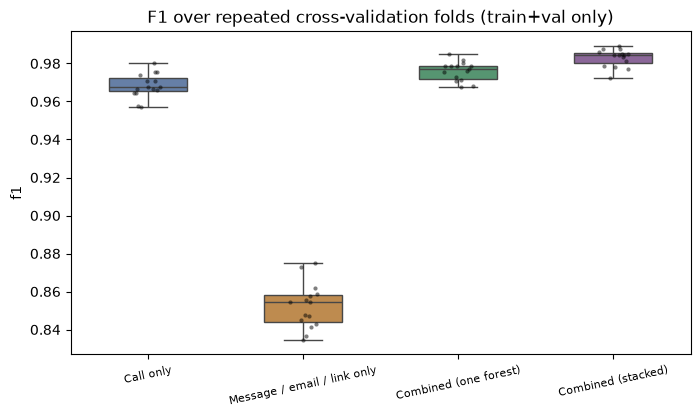

,a,b,mean_diff,std_diff,share_a_wins
0,combined_early,call_only,0.0077,0.0057,0.9333
1,combined_stacked,call_only,0.0147,0.0066,1.0000
2,combined_early,message_only,0.1237,0.0117,1.0000
3,combined_stacked,combined_early,0.0070,0.0032,0.9333


In [4]:
R.plot_cv_scores(t['folds'], 'f1'); plt.show()
pd.read_csv(C.TABLES_DIR / 'cv_paired_differences.csv').round(4)

`share_a_wins` = fraction of CV folds where model *a* has the higher F1 than model *b*; `mean_diff` is the average F1 gap.

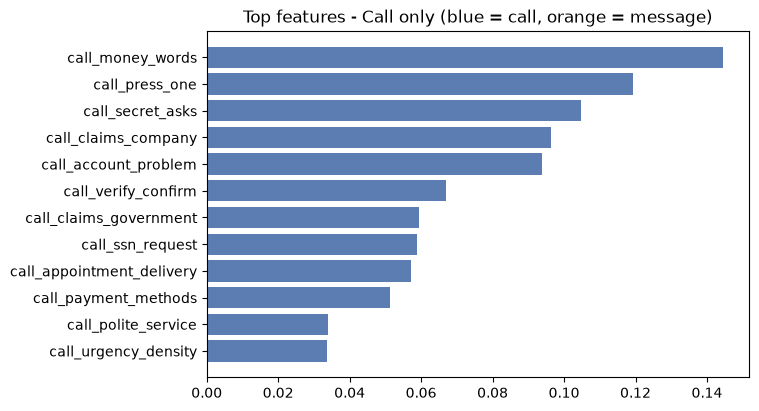

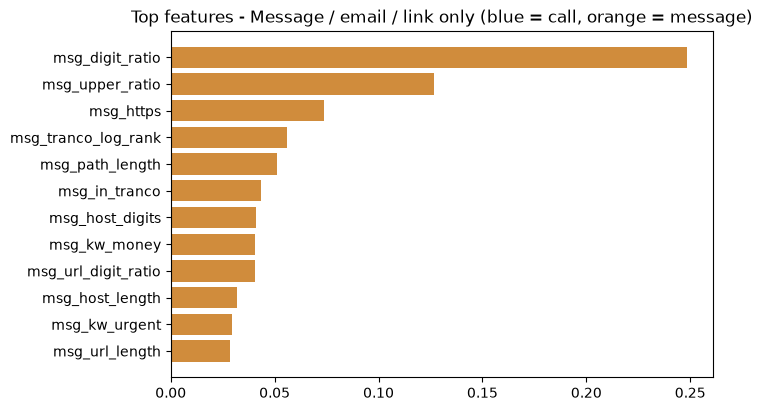

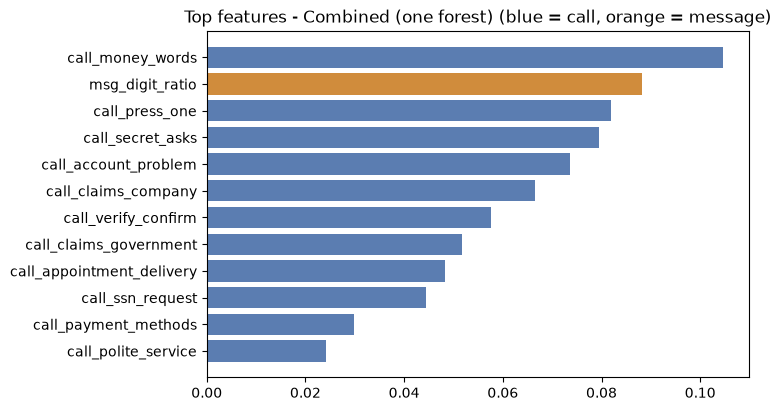

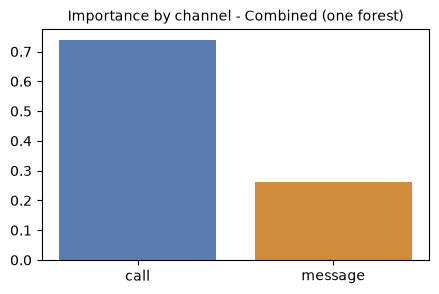

In [5]:
from toadwatch.modeling import feature_importance
imp = feature_importance(t['models'])
for v in ['call_only', 'message_only', 'combined_early']:
    R.plot_feature_importance(imp, v, name=f'v2_09_importance_{v}')
R.plot_channel_importance(imp, 'combined_early', 'v2_10_channel_importance')
plt.show()

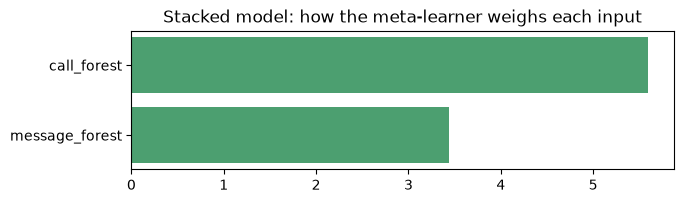

call_forest       5.595
message_forest    3.435
Name: weight, dtype: float64

In [6]:
sf = t['models']['combined_stacked'][0]
R.plot_meta_weights(sf.meta_weights(), 'v2_11_meta_weights'); plt.show()
sf.meta_weights().round(3)

/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144

/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144

/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144

/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144

/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144

/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144

... (11 outputs left out)

/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144

/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144

/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144

/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/rush/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144

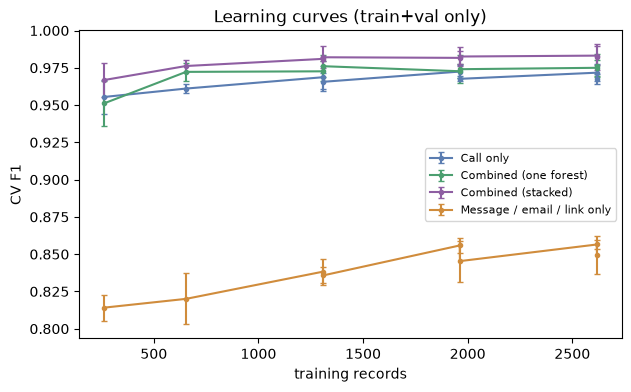

In [7]:
lc = W.learning_curves()      # ~3 minutes
R.plot_learning_curve(lc, 'v2_08_learning_curve'); plt.show()

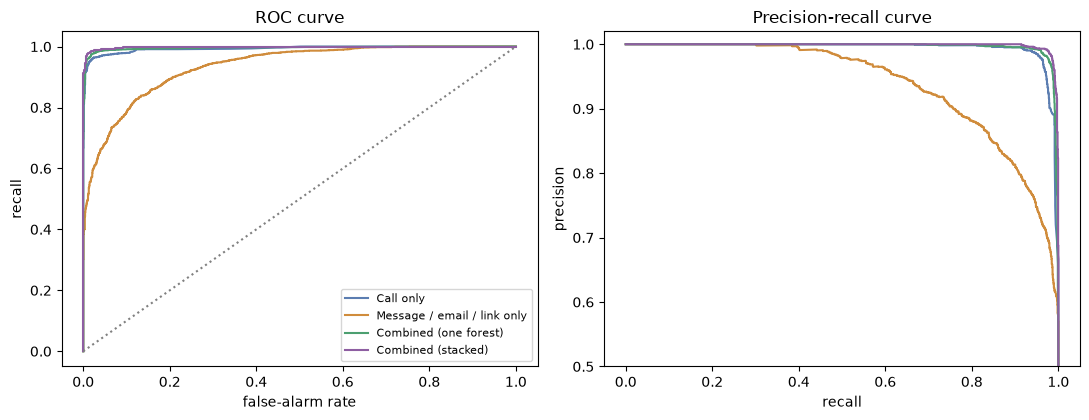

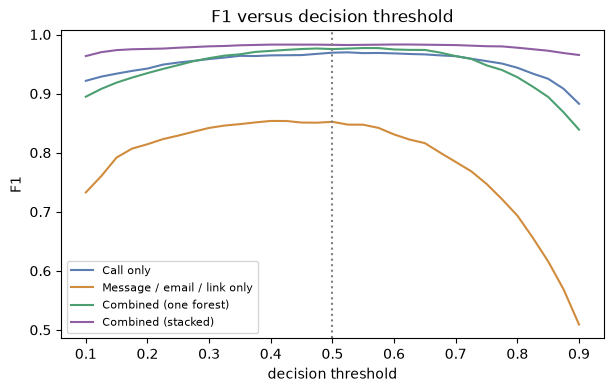

In [8]:
probas = {c[2:]: t['oof'][c] for c in t['oof'] if c.startswith('p_')}
R.plot_roc_pr(t['oof']['y'], probas, 'v2_05_cv_roc_pr'); R.plot_threshold_sweep(t['oof']['y'], probas, 'v2_07_cv_threshold_sweep'); plt.show()